In [1]:
import pickle, numpy as np

with open("data/s01.dat", "rb") as f:
    d = pickle.load(f, encoding="latin1")

print(d.keys())
print(d["data"].shape)
print(d["labels"].shape)
print(d["labels"][:5])

FileNotFoundError: [Errno 2] No such file or directory: 'data/s01.dat'

In [2]:
import os
print(os.getcwd())
print(os.listdir("."))

C:\Users\ishap\Downloads\AI for Neuromorphic emotion behavior modeling
['.ipynb_checkpoints', 'data', 'load_data.py', 'notebook.ipynb', 'preprocess.py', 'train.py']


In [3]:
import kagglehub
path = kagglehub.dataset_download("guneethpalakurthy/deap-dataset")
print(path)

for root, dirs, files in os.walk(path):
    print(root, files[:5])

ModuleNotFoundError: No module named 'kagglehub'

In [4]:
import os
print(os.listdir("data"))

['.ipynb_checkpoints', 's01 (1).dat', 's02.dat', 's03.dat', 's04.dat', 's05.dat', 's06.dat', 's07.dat', 's08.dat', 's09.dat', 's10.dat', 's11.dat', 's12.dat', 's13.dat', 's14.dat', 's15.dat', 's16.dat', 's17.dat', 's18.dat', 's19.dat', 's20.dat', 's21.dat', 's22.dat', 's23.dat', 's24.dat', 's25.dat', 's26.dat', 's27.dat', 's28.dat', 's29.dat', 's30.dat', 's31.dat', 's32.dat']


In [5]:
import os
print(os.listdir("data"))

['.ipynb_checkpoints', 's01 (1).dat', 's02.dat', 's03.dat', 's04.dat', 's05.dat', 's06.dat', 's07.dat', 's08.dat', 's09.dat', 's10.dat', 's11.dat', 's12.dat', 's13.dat', 's14.dat', 's15.dat', 's16.dat', 's17.dat', 's18.dat', 's19.dat', 's20.dat', 's21.dat', 's22.dat', 's23.dat', 's24.dat', 's25.dat', 's26.dat', 's27.dat', 's28.dat', 's29.dat', 's30.dat', 's31.dat', 's32.dat']


In [6]:
import os
os.rename("data/s01 (1).dat", "data/s01.dat")
print(sorted(os.listdir("data"))[:4])

['.ipynb_checkpoints', 's01.dat', 's02.dat', 's03.dat']


In [7]:
import pickle, numpy as np

with open("data/s01.dat", "rb") as f:
    d = pickle.load(f, encoding="latin1")

print(d.keys())
print(d["data"].shape)
print(d["labels"].shape)
print(d["labels"][:5])

dict_keys(['labels', 'data'])
(40, 40, 8064)
(40, 4)
[[7.71 7.6  6.9  7.83]
 [8.1  7.31 7.28 8.47]
 [8.58 7.54 9.   7.08]
 [4.94 6.01 6.12 8.06]
 [6.96 3.92 7.19 6.05]]


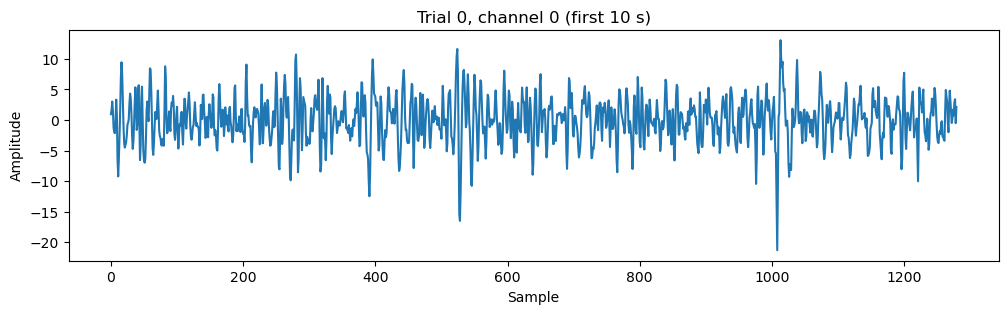

In [8]:
import matplotlib.pyplot as plt

eeg = d["data"][0, 0, :]            # trial 0, channel 0
plt.figure(figsize=(12, 3))
plt.plot(eeg[:1280])                # first 10 seconds (128 Hz)
plt.title("Trial 0, channel 0 (first 10 s)")
plt.xlabel("Sample"); plt.ylabel("Amplitude")
plt.show()

High valence: 19 / 40
High arousal: 24 / 40


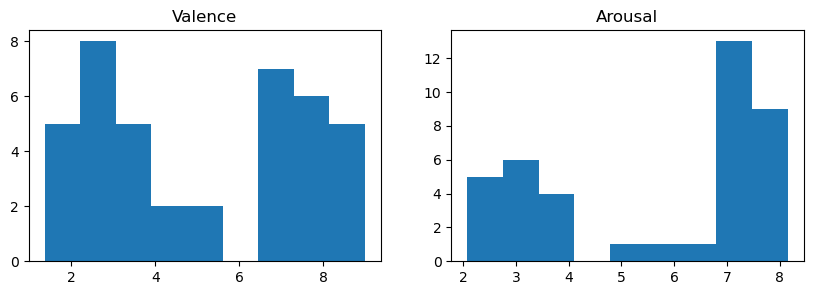

In [9]:
labels = d["labels"]
valence, arousal = labels[:, 0], labels[:, 1]

print("High valence:", (valence > 5).sum(), "/ 40")
print("High arousal:", (arousal > 5).sum(), "/ 40")

fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].hist(valence, bins=9); ax[0].set_title("Valence")
ax[1].hist(arousal, bins=9); ax[1].set_title("Arousal")
plt.show()

In [11]:
from scipy.signal import butter, filtfilt

def bandpass(x, low=4, high=45, fs=128, order=4):
    b, a = butter(order, [low, high], btype="band", fs=fs)
    return filtfilt(b, a, x, axis=-1)

def preprocess_subject(d, win=512, step=256):
    data = d["data"][:, :32, 384:]               # (40, 32, 7680): EEG only, no baseline
    data = bandpass(data)                         # filter along time
    # normalize each channel across the subject's data
    mean = data.mean(axis=(0, 2), keepdims=True)
    std = data.std(axis=(0, 2), keepdims=True)
    data = (data - mean) / std

    y_trial = (d["labels"][:, :2] > 5).astype(int)   # valence, arousal

    X, y, trial_id = [], [], []
    for t in range(data.shape[0]):
        for start in range(0, data.shape[2] - win + 1, step):
            X.append(data[t, :, start:start + win])
            y.append(y_trial[t])
            trial_id.append(t)
    return np.array(X), np.array(y), np.array(trial_id)

X, y, trial_id = preprocess_subject(d)
print(X.shape, y.shape)    # expect about (1160, 32, 512) and (1160, 2)

(1160, 32, 512) (1160, 2)


In [1]:
%pip install scipy numpy scikit-learn matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
python.exe -m pip install --upgrade pip

SyntaxError: invalid syntax (842801469.py, line 1)

In [3]:
python.exe -m %pip install --upgrade %pip

SyntaxError: invalid syntax (802476326.py, line 1)

In [4]:
code = '''import pickle, os

def load_subject(sid, data_dir="data"):
    with open(os.path.join(data_dir, f"s{sid:02d}.dat"), "rb") as f:
        return pickle.load(f, encoding="latin1")
'''
with open("load_data.py", "w") as f:
    f.write(code)
print(open("load_data.py").read())

import pickle, os

def load_subject(sid, data_dir="data"):
    with open(os.path.join(data_dir, f"s{sid:02d}.dat"), "rb") as f:
        return pickle.load(f, encoding="latin1")



In [1]:
%pip install snntorch

Note: you may need to restart the kernel to use updated packages.
